# Semana 16: Procesamiento de señales neuronales

**Objetivo:** analizar una señal ruidosa en el dominio del tiempo y de la frecuencia, y predecir
cuánto atenúa un filtro cada componente.

## Señal

$$x(t) = \sin(2\pi\cdot 8t) + 0.5\,\sin(2\pi\cdot 25t) + \varepsilon(t), \qquad \varepsilon \sim \mathcal{N}(0, 0.7^2)$$

muestreada a $f_s = 200$ Hz durante 5 s. Solo se pueden representar frecuencias hasta la
**frecuencia de Nyquist** $f_s/2 = 100$ Hz; la resolución espectral es $1/T = 0.2$ Hz.

## Espectro

La amplitud de cada componente se estima con la FFT: $A(f_k) = \frac{2}{N}\,|X_k|$, con
$X_k = \sum_n x_n e^{-2\pi i k n / N}$.

## Filtro de media móvil

Promediar $M = 9$ muestras es un filtro pasa-bajos con respuesta en frecuencia

$$|H(f)| = \left|\frac{\sin(\pi f M / f_s)}{M \sin(\pi f / f_s)}\right|$$

**Predicción:** $|H(8\,\text{Hz})| \approx 0.80$ y $|H(25\,\text{Hz})| \approx 0.11$: el filtro
conserva casi toda la componente de 8 Hz y elimina casi toda la de 25 Hz.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience.outputs import save_data, save_figure

WEEK = 16
SAMPLE_RATE_HZ = 200.0
WINDOW = 9
rng = np.random.default_rng(16)
time_s = np.arange(0.0, 5.0, 1.0 / SAMPLE_RATE_HZ)
clean = np.sin(2 * np.pi * 8 * time_s) + 0.5 * np.sin(2 * np.pi * 25 * time_s)
noisy = clean + rng.normal(0.0, 0.7, time_s.size)
filtered = np.convolve(noisy, np.ones(WINDOW) / WINDOW, mode="same")
frequencies = np.fft.rfftfreq(time_s.size, d=1.0 / SAMPLE_RATE_HZ)


def amplitude_spectrum(signal: np.ndarray) -> np.ndarray:
    return np.abs(np.fft.rfft(signal - signal.mean())) / signal.size * 2


def moving_average_gain(frequency_hz: np.ndarray) -> np.ndarray:
    frequency_hz = np.asarray(frequency_hz, dtype=float)
    angle = np.pi * frequency_hz / SAMPLE_RATE_HZ
    with np.errstate(invalid="ignore", divide="ignore"):
        gain = np.abs(np.sin(WINDOW * angle) / (WINDOW * np.sin(angle)))
    return np.where(frequency_hz == 0, 1.0, gain)


noisy_spectrum = amplitude_spectrum(noisy)
filtered_spectrum = amplitude_spectrum(filtered)

## Figura

Arriba: primer segundo de la señal y su versión filtrada. Centro: espectro de amplitud antes y
después del filtro. Abajo: ganancia teórica del filtro $|H(f)|$.

Saved: weeks/week_16_signal_processing/outputs/signal_processing.png
Saved: weeks/week_16_signal_processing/outputs/signal_processing.npz


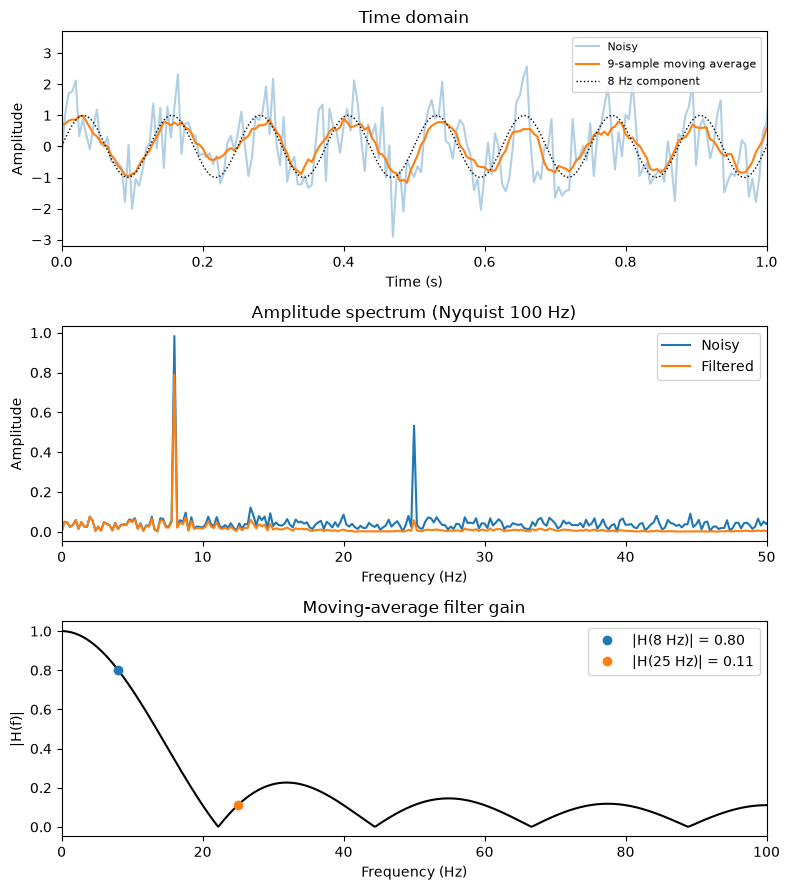

In [2]:
figure, axes = plt.subplots(3, 1, figsize=(8, 9))
axes[0].plot(time_s, noisy, alpha=0.35, label="Noisy")
axes[0].plot(time_s, filtered, label=f"{WINDOW}-sample moving average")
axes[0].plot(time_s, np.sin(2 * np.pi * 8 * time_s), "k:", linewidth=1, label="8 Hz component")
axes[0].set(xlim=(0, 1), xlabel="Time (s)", ylabel="Amplitude", title="Time domain")
axes[0].legend(fontsize=8, loc="upper right")
axes[1].plot(frequencies, noisy_spectrum, label="Noisy")
axes[1].plot(frequencies, filtered_spectrum, label="Filtered")
axes[1].set(xlim=(0, 50), xlabel="Frequency (Hz)", ylabel="Amplitude", title=f"Amplitude spectrum (Nyquist {SAMPLE_RATE_HZ / 2:g} Hz)")
axes[1].legend()
axes[2].plot(frequencies, moving_average_gain(frequencies), "k-")
for frequency in (8, 25):
    axes[2].plot(frequency, moving_average_gain(frequency), "o", label=f"|H({frequency} Hz)| = {float(moving_average_gain(frequency)):.2f}")
axes[2].set(xlim=(0, 100), xlabel="Frequency (Hz)", ylabel="|H(f)|", title="Moving-average filter gain")
axes[2].legend()
save_figure(WEEK, figure, "signal_processing.png")
save_data(WEEK, "signal_processing.npz", time_s=time_s, noisy=noisy, filtered=filtered, frequencies_hz=frequencies,
          noisy_spectrum=noisy_spectrum, filtered_spectrum=filtered_spectrum)

## Validación

- Los dos picos más altos del espectro están en 8 y 25 Hz, con amplitudes ≈ 1 y ≈ 0.5.
- La atenuación medida en cada pico coincide con la ganancia teórica del filtro (±0.1).

In [3]:
peaks = np.sort(frequencies[np.argsort(noisy_spectrum)[-2:]])
peak_index = {frequency: int(np.argmin(np.abs(frequencies - frequency))) for frequency in (8, 25)}
assert np.allclose(peaks, [8.0, 25.0])
assert abs(noisy_spectrum[peak_index[8]] - 1.0) < 0.15 and abs(noisy_spectrum[peak_index[25]] - 0.5) < 0.15
for frequency, index in peak_index.items():
    measured = filtered_spectrum[index] / noisy_spectrum[index]
    predicted = float(moving_average_gain(frequency))
    assert abs(measured - predicted) < 0.1, (frequency, measured, predicted)
    print(f"{frequency} Hz: measured gain {measured:.2f}, predicted {predicted:.2f}")

8 Hz: measured gain 0.80, predicted 0.80
25 Hz: measured gain 0.11, predicted 0.11


## Interpretación y límites

- La media móvil es fácil pero tiene lóbulos laterales (la ganancia no cae a 0 de forma
  monótona); filtros diseñados (Butterworth, FIR con ventana) dan cortes más limpios.
- `mode="same"` introduce efectos de borde en los primeros y últimos 4 puntos.
- Una componente por encima de 100 Hz aparecería *plegada* (aliasing) a una frecuencia falsa.

**Para tu entrega:** añade una componente de 130 Hz y localiza en el espectro dónde aparece.